# How Planets Lose Their Moons around White Dwarfs

*Matthew Payne*

Between a quarter and a half of white dwarfs show heavy elements in their atmospheres. These elements typically sink out of sight within days to weeks, so they must be continually replenished, almost certainly by rocky material from a surviving planetary system. Asteroids are the usual suspects, but in the Solar System the moons outweigh the asteroid belt by more than two orders of magnitude. Could moons, freed from their planets, help to pollute white dwarfs?

This notebook reproduces, with REBOUND, the numerical experiments of

> M. J. Payne, D. Veras, M. J. Holman & B. T. Gänsicke (2016), *Liberating exomoons in white dwarf planetary systems*, MNRAS **457**, 217. [ADS](https://ui.adsabs.harvard.edu/abs/2016MNRAS.457..217P/abstract) · [arXiv:1603.09344](https://arxiv.org/abs/1603.09344)

which we refer to as PVHG16, and, at a much smaller scale, the follow-up

> M. J. Payne, D. Veras, B. T. Gänsicke & M. J. Holman (2017), *The fate of exomoons in white dwarf planetary systems*, MNRAS **464**, 2557. [ADS](https://ui.adsabs.harvard.edu/abs/2017MNRAS.464.2557P/abstract) · [arXiv:1610.01597](https://arxiv.org/abs/1610.01597)

(PVGH17).

We will:

1. Show that the star's mass loss, on its own, makes moons *more* secure: the planet's Hill sphere grows.
2. Repeat PVHG16's six single-encounter experiments, each with 10,000 test moons, to see which moons a close planet–planet flyby strips away.
3. Test PVHG16's second route to freedom: the shrinking of the Hill sphere when a scattered planet passes close to the white dwarf.
4. Follow a small ensemble of unstable planetary systems around a white dwarf, each planet with a moon, and compare how close the freed moons and the planets come to the white dwarf.

Figure and table numbers in the text refer to PVHG16 unless stated otherwise.

**Requirements:** `numpy`, `matplotlib` and `rebound` (version 4 or later).

**Run time:** the encounter, pericentre and scattering experiments take about two hours on a 12-core laptop and are cached in `cache/`, so the notebook normally runs in a few minutes (the mass-loss integration, about two minutes, is always run). Set `RECOMPUTE = True` to redo them, or `QUICK = True` for 1,000 moons per encounter.

In [1]:
import os
import time
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np

import exomoons as ex   # helper module in this folder: the set-ups and integrations

QUICK = False            # True: 1,000 moons per encounter instead of 10,000
RECOMPUTE = False        # True: ignore cached results and integrate again
N_MOONS = 1_000 if QUICK else 10_000
CACHE = "cache_quick" if QUICK else "cache"
NPROC = os.cpu_count()
print(f"Using {NPROC} processes; {N_MOONS:,} moons per encounter")

Using 12 processes; 10,000 moons per encounter


## 1. Mass loss makes moons safer

A moon orbits its planet rather than the star while it stays well inside the planet's Hill sphere, of radius

$$r_\mathrm{H} = a_\mathrm{p}(1 - e_\mathrm{p})\left(\frac{M_\mathrm{p}}{3M_\star}\right)^{1/3}$$

(PVHG16 Eq. 1); prograde moons are typically stable out to about $0.5\,r_\mathrm{H}$. As a star leaves the main sequence it sheds between half and four-fifths of its mass. When this mass loss is slow compared with the planet's orbit and isotropic, the planet's semi-major axis grows in proportion, $a_\mathrm{p} \propto 1/(M_\star + M_\mathrm{p})$, its eccentricity is unchanged on average, and the moon's orbit about the planet does not change at all. Combining the two,

$$\frac{r_\mathrm{H}^\mathrm{WD}}{r_\mathrm{H}^\mathrm{MS}} = \left(\frac{M_\star^\mathrm{MS}}{M_\star^\mathrm{WD}}\right)^{4/3}$$

(PVHG16 Eq. 8): the Hill sphere grows, and moons end up deeper inside it.

We check this with a direct integration: a Jupiter-mass planet at 10 au around a $1.5\,M_\odot$ star, with three moons at 0.05, 0.2 and 0.4 of its Hill radius. The star loses mass steadily down to $0.6\,M_\odot$ over 20,000 years (about 800 of the planet's orbits, so slowly enough to be "adiabatic"), and we follow the system for as long again. The star's mass is lowered in small steps between integrations, leaving positions and velocities unchanged, as isotropic mass loss does.

<>:14: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:14: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
/var/folders/67/j23cbc8x5r3b_1cy48v0rf4m0000gq/T/ipykernel_44495/561909234.py:14: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
  a1.set(xlabel="time (thousand years)", ylabel="star's mass (M$_\odot$)", title="The star loses mass")


Integrated in 76 s
Planet's semi-major axis grew by 2.4976 (expected 2.4976)
Hill radius grew by 3.390 (expected (1.5/0.6)^(4/3) = 3.393)
Moon starting at 0.05 r_H: semi-major axis changed by -0.01%, now at 0.015 r_H
Moon starting at 0.2 r_H: semi-major axis changed by -0.40%, now at 0.059 r_H
Moon starting at 0.4 r_H: semi-major axis changed by -1.10%, now at 0.117 r_H


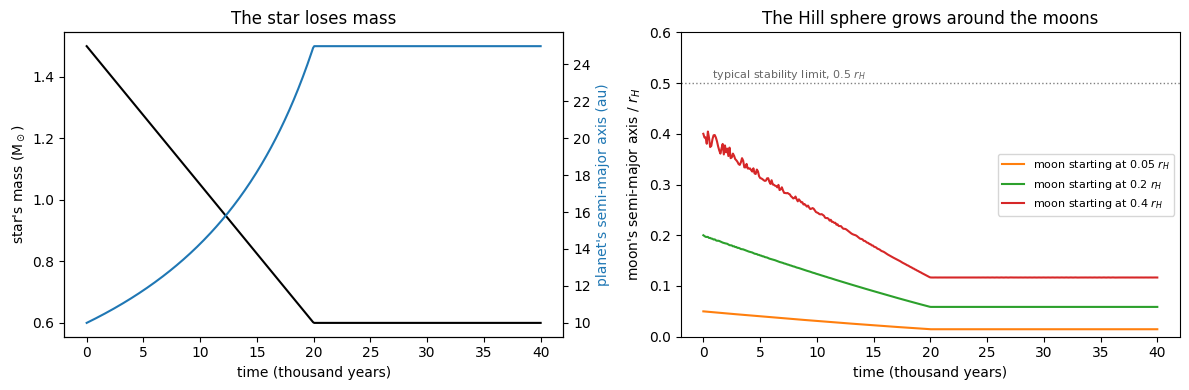

In [2]:
t0 = time.time()
ml = ex.mass_loss_run(m0=1.5, m1=0.6, t_loss_yr=2.0e4)
print(f"Integrated in {time.time() - t0:.0f} s")
grow_a = ml["a_p"][-1] / ml["a_p"][0]
grow_h = ml["r_H"][-1] / ml["r_H"][0]
print(f"Planet's semi-major axis grew by {grow_a:.4f} (expected {(1.5 + ex.M_JUP) / (0.6 + ex.M_JUP):.4f})")
print(f"Hill radius grew by {grow_h:.3f} (expected (1.5/0.6)^(4/3) = {(1.5 / 0.6) ** (4 / 3):.3f})")
for j, f in enumerate([0.05, 0.2, 0.4]):
    print(f"Moon starting at {f} r_H: semi-major axis changed by {100 * (ml['a_m'][-1, j] / ml['a_m'][0, j] - 1):+.2f}%, "
          f"now at {ml['a_m'][-1, j] / ml['r_H'][-1]:.3f} r_H")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(ml["t"] / 1e3, ml["m_star"], color="k")
a1.set(xlabel="time (thousand years)", ylabel="star's mass (M$_\odot$)", title="The star loses mass")
a1b = a1.twinx()
a1b.plot(ml["t"] / 1e3, ml["a_p"], color="C0")
a1b.set_ylabel("planet's semi-major axis (au)", color="C0")
for j, (f, col) in enumerate(zip([0.05, 0.2, 0.4], ["C1", "C2", "C3"])):
    a2.plot(ml["t"] / 1e3, ml["a_m"][:, j] / ml["r_H"], color=col, label=f"moon starting at {f} $r_H$")
a2.axhline(0.5, color="0.5", ls=":", lw=1)
a2.text(0.5, 0.51, " typical stability limit, 0.5 $r_H$", color="0.4", fontsize=8)
a2.set(xlabel="time (thousand years)", ylabel="moon's semi-major axis / $r_H$", ylim=(0, 0.6),
       title="The Hill sphere grows around the moons")
a2.legend(fontsize=8)
fig.tight_layout()
plt.show()

The planet's orbit and Hill radius grow exactly as predicted, while the moons' orbits barely change (the outermost moon, at 0.4 $r_\mathrm{H}$, is gently perturbed by the star's tide). After mass loss each moon sits at less than a third of its former fraction of the Hill radius.

PVHG16 computed how much the Hill radius grows for real stars with the SSE stellar-evolution code. Their ratios, and the white-dwarf masses that Eq. 8 implies for them, are:

In [3]:
SSE = {1: 2.39, 2: 4.57, 3: 6.35, 4: 7.65, 5: 8.55, 6: 9.16, 7: 9.53, 8: 9.83}   # PVHG16 Sec. 2
print("progenitor mass   r_H(WD)/r_H(MS)   implied white-dwarf mass")
for m, r in SSE.items():
    print(f"   {m} Msun             {r:5.2f}              {m / r ** 0.75:5.2f} Msun")

progenitor mass   r_H(WD)/r_H(MS)   implied white-dwarf mass
   1 Msun              2.39               0.52 Msun
   2 Msun              4.57               0.64 Msun
   3 Msun              6.35               0.75 Msun
   4 Msun              7.65               0.87 Msun
   5 Msun              8.55               1.00 Msun
   6 Msun              9.16               1.14 Msun
   7 Msun              9.53               1.29 Msun
   8 Msun              9.83               1.44 Msun


The Hill sphere grows by a factor of 2 to 10, entrenching the moons. Freeing them needs something violent.

## 2. A single close encounter

Mass loss can also destabilise a planetary system, sometimes billions of years after the star has become a white dwarf (Veras & Gänsicke 2015). The planets then scatter off one another, with many close encounters. PVHG16's Figures 2 and 3 show how close and how fast these encounters were in the simulations of Veras & Gänsicke (2015); here we repeat their experiment on what a *single* such encounter does to a planet's moons.

The set-up (PVHG16 Sec. 4.1 and Table 1):

* A parent planet on a circular orbit at 30 au around a $1\,M_\odot$ star, and a second planet of the same mass that flies past it, with closest-approach distance $q$ and relative speed at closest approach $V_q$.
* 10,000 test moons around the parent, with semi-major axes uniform in $\log a$ from the planet's radius to $0.5\,r_\mathrm{H}$, eccentricities uniform between 0 and 1 (keeping the pericentre above the planet's surface and the apocentre inside $0.5\,r_\mathrm{H}$), inclinations uniform between 0° and 180°, and random orientations.
* Six encounters, three for Jupiter-mass planets and three for Earth-mass planets, from common and distant to rare and very close:

| | $q$ (au) | $V_q$ (au/day) | planets | $r_\mathrm{H}$ (au) | $t_\mathrm{sim}$ (days) | PVHG16's note |
|---|---|---|---|---|---|---|
| A | 10 | $10^{-3}$ | Jupiter | 2.0 | 25,000 | common, little effect |
| B | 1 | $10^{-3}$ | Jupiter | 2.0 | 25,000 | relatively rare, destructive |
| C | 1 | $3\times10^{-4}$ | Jupiter | 2.0 | 8,300 | very rare, highly destructive |
| X | 1 | $10^{-3}$ | Earth | 0.3 | 3,600 | common, little effect |
| Y | 0.03 | $3\times10^{-4}$ | Earth | 0.3 | 12,000 | relatively rare, destructive |
| Z | 0.01 | $3\times10^{-4}$ | Earth | 0.3 | 12,000 | very rare, highly destructive |

PVHG16 started each encounter with the planets $4\,r_\mathrm{H}$ apart and ran it until they were $4\,r_\mathrm{H}$ apart again. That cannot be done for every case: in A the closest approach (10 au) is already beyond $4\,r_\mathrm{H}$ (8 au), and in C, Y and Z the relative speed is below the two planets' mutual escape speed, so they are temporarily captured and do not separate within any reasonable time. We therefore use their stated durations: we set the planets up at closest approach, integrate back by $t_\mathrm{sim}/2$, add the moons there, and integrate forward for $t_\mathrm{sim}$, so that the encounter falls in the middle. PVHG16 do not give the direction of the flyby; ours crosses the parent's orbit, moving radially relative to it, as planets on eccentric, crossing orbits do (`ex.flyby_massive`). A moon counts as surviving if, at the end, it is bound to the parent planet and inside its Hill radius.

The moons are integrated with IAS15, sorted by semi-major axis into batches of 25 so that each batch's shared time step suits all its moons.

In [4]:
CASES = ["A", "B", "C", "X", "Y", "Z"]
runs = {}
t0 = time.time()
with Pool(NPROC) as pool:
    for case in CASES:
        runs[case] = ex.flyby_cached(case, N_MOONS, pool, CACHE, recompute=RECOMPUTE)
        r = runs[case]
        print(f"{case}: {r['bound'].mean():6.1%} of moons survive; {int(r['captured'].sum())} captured by the flyby planet")
print(f"({time.time() - t0:.0f} s)")

A: 100.0% of moons survive; 0 captured by the flyby planet
B:  96.9% of moons survive; 90 captured by the flyby planet
C:  69.9% of moons survive; 666 captured by the flyby planet
X: 100.0% of moons survive; 0 captured by the flyby planet
Y:  74.1% of moons survive; 389 captured by the flyby planet
Z:  31.3% of moons survive; 28 captured by the flyby planet
(0 s)


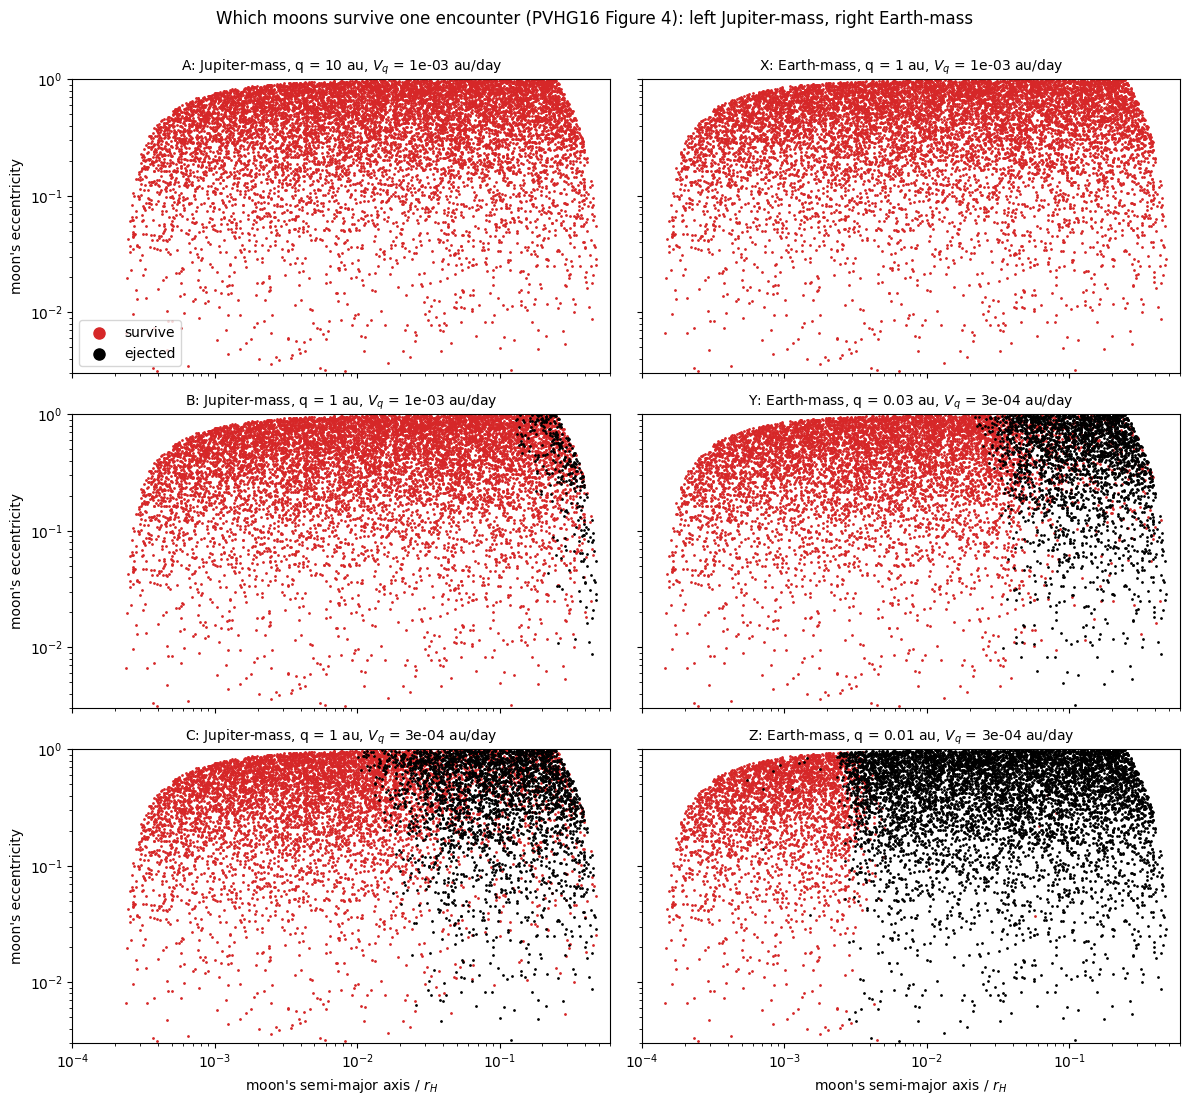

In [5]:
fig, axs = plt.subplots(3, 2, figsize=(12, 11), sharex=True, sharey=True)
for ax, case in zip(axs.T.ravel(), CASES):
    r, c = runs[case], ex.FLYBYS[case]
    ej = ~r["bound"].astype(bool)
    ax.scatter(r["a_rH"][~ej], r["e"][~ej], s=1, color="C3", rasterized=True, label="survive")
    ax.scatter(r["a_rH"][ej], r["e"][ej], s=1, color="k", rasterized=True, label="ejected")
    planet = "Jupiter" if c["m_p"] > 1e-4 else "Earth"
    ax.set_title(f"{case}: {planet}-mass, q = {c['q']:g} au, $V_q$ = {c['vq']:.0e} au/day", fontsize=10)
    ax.set(xscale="log", yscale="log", xlim=(1e-4, 0.6), ylim=(3e-3, 1))
for ax in axs[-1]:
    ax.set_xlabel("moon's semi-major axis / $r_H$")
for ax in axs[:, 0]:
    ax.set_ylabel("moon's eccentricity")
axs[0, 0].legend(markerscale=8, loc="lower left")
fig.suptitle("Which moons survive one encounter (PVHG16 Figure 4): left Jupiter-mass, right Earth-mass", y=1.0)
fig.tight_layout()
plt.show()

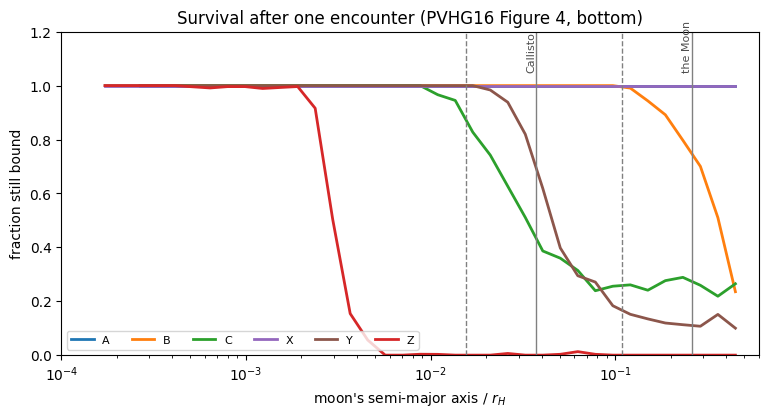

Grey lines: Callisto and the Moon today (solid) and after the Hill sphere has grown 2.39-fold, as for a 1 Msun progenitor (dashed).


In [6]:
def survival_curve(r, bins=np.logspace(-4, np.log10(0.5), 40)):
    idx = np.digitize(r["a_rH"], bins) - 1
    frac = np.array([r["bound"][idx == k].mean() if np.sum(idx == k) >= 20 else np.nan for k in range(len(bins) - 1)])
    return np.sqrt(bins[1:] * bins[:-1]), frac

# Solar System moons, as fractions of their planets' present Hill radii
R_H_JUP = ex.hill_radius(5.2026, 0.0489, ex.M_JUP, 1.0) * ex.AU_KM
R_H_EARTH = ex.hill_radius(1.0, 0.0167, ex.M_EARTH, 1.0) * ex.AU_KM
SOLAR = {"Callisto": 1.8827e6 / R_H_JUP, "the Moon": 3.844e5 / R_H_EARTH}

fig, ax = plt.subplots(figsize=(9, 4.2))
for case, col in zip(CASES, ["C0", "C1", "C2", "C4", "C5", "C3"]):
    x, f = survival_curve(runs[case])
    ax.plot(x, f, color=col, lw=2, label=f"{case}")
for name, x in SOLAR.items():
    ax.axvline(x, color="0.5", lw=1)
    ax.axvline(x / 2.39, color="0.5", lw=1, ls="--")
    ax.text(x, 1.05, name, rotation=90, fontsize=8, va="bottom", ha="right", color="0.3")
ax.set(xscale="log", xlim=(1e-4, 0.6), ylim=(0, 1.2), xlabel="moon's semi-major axis / $r_H$", ylabel="fraction still bound",
       title="Survival after one encounter (PVHG16 Figure 4, bottom)")
ax.legend(ncol=6, loc="lower left", fontsize=8)
plt.show()
print("Grey lines: Callisto and the Moon today (solid) and after the Hill sphere has grown 2.39-fold, "
      "as for a 1 Msun progenitor (dashed).")

In [7]:
with Pool(NPROC) as pool:
    alt = ex.flyby_cached("C", N_MOONS, pool, CACHE, recompute=RECOMPUTE, geometry="overtaking")
print(f"Encounter C with an overtaking flyby instead: {alt['bound'].mean():.1%} of moons survive "
      f"(crossing flyby: {runs['C']['bound'].mean():.1%})")

Encounter C with an overtaking flyby instead: 70.2% of moons survive (crossing flyby: 69.9%)


Distant encounters (A and X) leave every moon in place. Closer ones strip the outer Hill sphere: in B, moons beyond about $0.15\,r_\mathrm{H}$ start to be lost, and only about a quarter of those near $0.5\,r_\mathrm{H}$ survive; Y removes most moons beyond a few hundredths of $r_\mathrm{H}$; and Z, the closest, removes almost every moon beyond $0.003\,r_\mathrm{H}$.

Compared with PVHG16's Figure 4 (bottom), B, Y and Z agree well: the distance at which moons start to be lost, and the distance at which half are lost, match to within a few tens of per cent. C differs. Our losses begin at about $0.01\,r_\mathrm{H}$ rather than PVHG16's $0.006\,r_\mathrm{H}$, and about a quarter of the outer moons survive, where PVHG16 lost nearly all of them. In C the two planets pass more slowly than their mutual escape speed, so they are temporarily captured, and the result depends on how long the pair is followed; PVHG16 and we necessarily treat this differently (Sec. 2 above). The direction of the flyby, which the paper does not give, is not the cause: an overtaking flyby gives the same survival as a crossing one.

What would happen to moons like those of the Solar System? After the Hill sphere has grown 2.39-fold (dashed grey lines), a Callisto-like moon sits at $0.016\,r_\mathrm{H}$: it survives B, and 89% of such moons survive C. A Moon-like orbit around an Earth-mass planet, at $0.11\,r_\mathrm{H}$, survives Y only 17% of the time and Z never. PVHG16 chose B and Y so that each planet in a scattering system can expect at least one encounter at least this destructive, so a moon like ours would very probably be set free.

## 3. A close pass by the white dwarf

Scattering also throws planets onto eccentric orbits. PVHG16's Figure 5 shows that in the simulations of Veras & Gänsicke (2015), about a third of the Jupiter-mass systems, and on average every Earth-mass system, had a planet reach a pericentre of a tenth of the innermost planet's original distance or less. Since $r_\mathrm{H} \propto a_\mathrm{p}(1-e_\mathrm{p})$, the Hill sphere at pericentre is correspondingly small, and PVHG16 argue that moons orbiting beyond it will be lost: a pericentre of a tenth of the original distance shrinks the Hill radius tenfold, enough to free the Moon from an Earth-like planet.

The Hill radius, though, is a statement about where the star's tide beats the planet's pull on average; at pericentre it applies only briefly. To see how quickly moons actually escape, we integrate an Earth-mass planet on an orbit with semi-major axis 10 au around a $0.6\,M_\odot$ white dwarf, from apocentre through one pericentre passage and back, with moons on circular orbits at a range of distances, expressed in units of the Hill radius *at pericentre*, $r_\mathrm{H}(q)$.

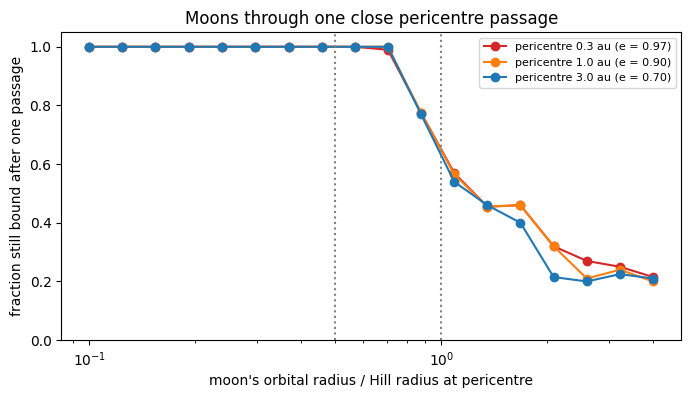

pericentre 0.3 au: all moons survive out to 0.7 r_H(q); half survive at 1.2 r_H(q); 22% survive at 4 r_H(q)
pericentre 1.0 au: all moons survive out to 0.7 r_H(q); half survive at 1.2 r_H(q); 20% survive at 4 r_H(q)
pericentre 3.0 au: all moons survive out to 0.7 r_H(q); half survive at 1.2 r_H(q); 21% survive at 4 r_H(q)


In [8]:
FRACS = np.round(np.geomspace(0.1, 4, 18), 3)
N_EACH = 60 if QUICK else 200
PERI = [0.3, 1.0, 3.0]                 # pericentre distances (au) for a planet with a = 10 au
peri_path = os.path.join(CACHE, f"pericentre_{N_EACH}.npz")
if os.path.exists(peri_path) and not RECOMPUTE:
    z = np.load(peri_path)
    peri_runs = {q: z[f"q{q}"] for q in PERI}
else:
    peri_runs = {}
    t0 = time.time()
    with Pool(NPROC) as pool:
        for q in PERI:
            fr = np.repeat(FRACS, N_EACH)
            # moons are split across NPROC batches (seeds 100, 101, ...)
            jobs = [(q, 10.0, ex.M_EARTH, 0.6, fr[k::NPROC], 100 + k) for k in range(NPROC)]
            parts = pool.map(ex.pericentre_batch, jobs)
            bound = np.empty(fr.size, bool)
            for k, b in enumerate(parts):
                bound[k::NPROC] = b
            peri_runs[q] = np.array([bound[fr == f].mean() for f in FRACS])
    os.makedirs(CACHE, exist_ok=True)
    np.savez(peri_path, **{f"q{q}": v for q, v in peri_runs.items()})
    print(f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(8, 4))
for q, col in zip(PERI, ["C3", "C1", "C0"]):
    ax.plot(FRACS, peri_runs[q], "o-", color=col, label=f"pericentre {q} au (e = {1 - q / 10:.2f})")
ax.axvline(1, color="0.5", ls=":")
ax.axvline(0.5, color="0.5", ls=":")
ax.set(xscale="log", ylim=(0, 1.05), xlabel="moon's orbital radius / Hill radius at pericentre",
       ylabel="fraction still bound after one passage", title="Moons through one close pericentre passage")
ax.legend(fontsize=8)
plt.show()
for q in PERI:
    p = peri_runs[q]
    k = np.argmax(p < 0.5)                              # first radius where fewer than half survive
    lf = np.log(FRACS)
    half = np.exp(lf[k - 1] + (0.5 - p[k - 1]) / (p[k] - p[k - 1]) * (lf[k] - lf[k - 1]))
    safe = FRACS[np.argmax(p < 0.99) - 1]
    print(f"pericentre {q} au: all moons survive out to {safe:.2g} r_H(q); half survive at {half:.2g} r_H(q); "
          f"{p[-1]:.0%} survive at {FRACS[-1]:g} r_H(q)")

The passage is brief, so moons survive well outside the Hill sphere at pericentre: every moon inside about $0.7\,r_\mathrm{H}(q)$ survives, half survive at about $1.2\,r_\mathrm{H}(q)$, and about a fifth survive even at $4\,r_\mathrm{H}(q)$. The three curves lie on top of each other: measured in units of $r_\mathrm{H}(q)$, the outcome does not depend on how close the planet comes. PVHG16's rule of thumb, that moons beyond $r_\mathrm{H}(q)$ are lost, is about right for where the losses happen, but a single passage frees only about half of the moons at $r_\mathrm{H}(q)$. The planet returns to pericentre every orbit (here every 41 years), so moons beyond about $0.7\,r_\mathrm{H}(q)$, left on disturbed orbits, are exposed again and again; we have followed only one passage.

## 4. What happens to the freed moons?

PVGH17 took 119 of Veras & Gänsicke's (2015) four-Earth-mass-planet systems, which stayed stable until the white-dwarf phase, added one moon to each planet about a million years before the planets first crossed orbits, and followed them for $10^8$ years. Their key result: freed moons reach much smaller pericentres about the white dwarf than the planets do, often within 0.01 au, close to the white dwarf's tidal-disruption radius.

Their systems took billions of years to become unstable and were followed for 100 million years, far beyond what a notebook can do. Instead we build systems that are unstable from the start: four Earth-mass planets around a $0.6\,M_\odot$ white dwarf, the innermost at 2 au, spaced by 3.5 mutual Hill radii, each with a moon on a circular orbit at 0.15 of its Hill radius. We follow 24 of them for 20,000 years. This is a test of the mechanism, not a reproduction of PVGH17's statistics. Planets are treated as points, so planet–planet collisions, which PVGH17's integrations included, cannot happen here.

In [9]:
N_SYS = 12 if QUICK else 24
T_SCATTER = 2.0e4
cache_path = os.path.join(CACHE, f"scatter_{N_SYS}_{int(T_SCATTER)}.npz")
if os.path.exists(cache_path) and not RECOMPUTE:
    z = np.load(cache_path)
    scat = [dict(t=z["t"], q=z["q"][k], inc=z["inc"][k], moon_bound=z["moon_bound"][k], n_pl=4) for k in range(N_SYS)]
else:
    t0 = time.time()
    with Pool(NPROC) as pool:
        scat = pool.map(ex.scattering_run, [(s, 4, ex.M_EARTH, 2.0, 3.5, 0.15, T_SCATTER, 2000) for s in range(N_SYS)], chunksize=1)
    np.savez_compressed(cache_path, t=scat[0]["t"], q=np.array([s["q"] for s in scat]),
                        inc=np.array([s["inc"] for s in scat]), moon_bound=np.array([s["moon_bound"] for s in scat]))
    print(f"({time.time() - t0:.0f} s)")

freed = np.array([~s["moon_bound"][-1] for s in scat])                 # (system, moon)
q_pl = np.array([np.nanmin(s["q"][:, :4], axis=0) for s in scat])      # minimum pericentre of each planet
q_mo = np.array([np.nanmin(np.where(s["moon_bound"], np.nan, s["q"][:, 4:]), axis=0) for s in scat])  # of each moon, once freed
print(f"{freed.sum()} of {freed.size} moons are free at the end; "
      f"{np.mean([np.all(s['moon_bound'][0]) for s in scat]):.0%} of systems started with all moons bound")

85 of 96 moons are free at the end; 100% of systems started with all moons bound


/var/folders/67/j23cbc8x5r3b_1cy48v0rf4m0000gq/T/ipykernel_44495/2237306637.py:17: RuntimeWarning: All-NaN slice encountered
  q_mo = np.array([np.nanmin(np.where(s["moon_bound"], np.nan, s["q"][:, 4:]), axis=0) for s in scat])  # of each moon, once freed


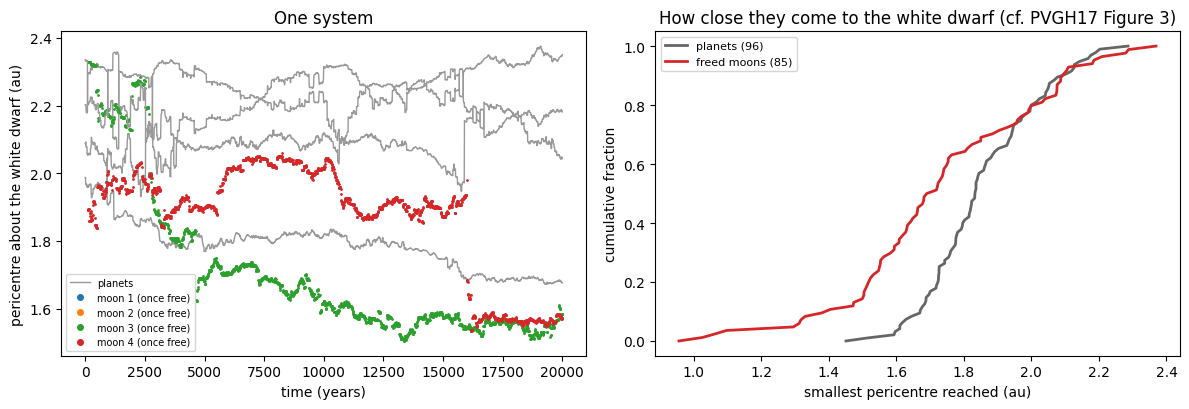

Smallest pericentre reached: planets 1.45 au (median 1.83 au), freed moons 0.96 au (median 1.69 au)
12% of freed moons came closer to the white dwarf than any planet did


In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
s = scat[0]
for k in range(4):
    a1.plot(s["t"], s["q"][:, k], color="0.6", lw=1, label="planets" if k == 0 else None)
    free = ~s["moon_bound"][:, k]
    a1.plot(s["t"][free], s["q"][free, 4 + k], ".", ms=2, color=f"C{k}", label=f"moon {k + 1} (once free)")
a1.set(xlabel="time (years)", ylabel="pericentre about the white dwarf (au)", title="One system")
a1.legend(fontsize=7, markerscale=4)

qm = q_mo[np.isfinite(q_mo)]
a2.plot(np.sort(q_pl.ravel()), np.linspace(0, 1, q_pl.size), color="0.4", lw=2, label=f"planets ({q_pl.size})")
a2.plot(np.sort(qm), np.linspace(0, 1, qm.size), color="C3", lw=2, label=f"freed moons ({qm.size})")
a2.set(xlabel="smallest pericentre reached (au)", ylabel="cumulative fraction",
       title="How close they come to the white dwarf (cf. PVGH17 Figure 3)")
a2.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"Smallest pericentre reached: planets {q_pl.min():.2f} au (median {np.median(q_pl):.2f} au), "
      f"freed moons {qm.min():.2f} au (median {np.median(qm):.2f} au)")
print(f"{np.mean(qm < q_pl.min()):.0%} of freed moons came closer to the white dwarf than any planet did")

Within 20,000 years most of the moons are set free. Once free, they are scattered by all four planets and wander further in than the planets themselves: the cumulative curve for the freed moons lies to the left of the planets', and about one freed moon in eight comes closer to the white dwarf than any planet does (0.96 au, against 1.45 au for the closest planet). This is the beginning of PVGH17's result. Over $10^8$ years, their planets never came inside about 1 au, while about 15% of the freed moons reached 0.1 au and about 5% reached 0.01 au, close to the distance at which the white dwarf's tides would break them up (about 0.011 au for their example). Our integrations are 5,000 times shorter, far too short for that slow, chaotic drift inwards, so no moon here gets near 0.1 au.

## Summary

* Slow, isotropic mass loss never frees a moon: the planet's Hill sphere grows by $(M_\star^\mathrm{MS}/M_\star^\mathrm{WD})^{4/3}$, by a factor of 2 to 10 for real stars, and the moons end up deeper inside it.
* Single close encounters between planets do free moons. Distant encounters are harmless; the closer encounters that a scattering planet can expect at least once strip the outer Hill sphere, and the rarest clear almost all of it. Our maps agree with PVHG16's for three of their four destructive encounters.
* A planet passing close to the white dwarf loses moons beyond about the Hill radius at pericentre, but a single brief passage frees only about half of the moons at that distance; inside about $0.7\,r_\mathrm{H}(q)$ they are safe.
* Freed moons are scattered further in than the planets. Over the $10^8$ years of PVGH17 this takes some of them close enough to the white dwarf to be torn apart; our short runs show only the start of that drift.

## Going further

* **Many encounters.** Each panel in Section 2 is a single encounter; PVHG16's Figure 3 shows that a scattering planet suffers tens to tens of thousands of them. Chaining encounters drawn from those distributions would show how quickly the outer moons are worn away.
* **Prograde and retrograde moons.** Retrograde moons are stable further out than prograde ones. Splitting the survival maps by the moon's inclination would show whether they also survive encounters better.
* **Longer scattering runs.** Section 4 covers only a short stretch of a white-dwarf system's life; PVGH17 followed theirs for $10^8$ years, and instabilities can continue for billions.
* **Tides and radiation.** Neither paper models tides or radiation on moons close to the white dwarf; PVGH17 estimate a tidal-disruption radius of about 0.01 au for a Callisto-like moon.

## References

* Chambers, J. E. 1999, *A hybrid symplectic integrator that permits close encounters between massive bodies*, MNRAS 304, 793. [ADS](https://ui.adsabs.harvard.edu/abs/1999MNRAS.304..793C/abstract)
* Hadjidemetriou, J. D. 1963, *Two-body problem with variable mass: A new approach*, Icarus 2, 440. [ADS](https://ui.adsabs.harvard.edu/abs/1963Icar....2..440H/abstract)
* Hurley, J. R., Pols, O. R. & Tout, C. A. 2000, *Comprehensive analytic formulae for stellar evolution as a function of mass and metallicity*, MNRAS 315, 543. [ADS](https://ui.adsabs.harvard.edu/abs/2000MNRAS.315..543H/abstract)
* Payne, M. J., Veras, D., Holman, M. J. & Gänsicke, B. T. 2016, *Liberating exomoons in white dwarf planetary systems*, MNRAS 457, 217. [ADS](https://ui.adsabs.harvard.edu/abs/2016MNRAS.457..217P/abstract)
* Payne, M. J., Veras, D., Gänsicke, B. T. & Holman, M. J. 2017, *The fate of exomoons in white dwarf planetary systems*, MNRAS 464, 2557. [ADS](https://ui.adsabs.harvard.edu/abs/2017MNRAS.464.2557P/abstract)
* Rein, H. & Liu, S.-F. 2012, *REBOUND: an open-source multi-purpose N-body code for collisional dynamics*, A&A 537, A128. [ADS](https://ui.adsabs.harvard.edu/abs/2012A&A...537A.128R/abstract)
* Rein, H. & Spiegel, D. S. 2015, *IAS15: a fast, adaptive, high-order integrator for gravitational dynamics, accurate to machine precision over a billion orbits*, MNRAS 446, 1424. [ADS](https://ui.adsabs.harvard.edu/abs/2015MNRAS.446.1424R/abstract)
* Veras, D. & Gänsicke, B. T. 2015, *Detectable close-in planets around white dwarfs through late unpacking*, MNRAS 447, 1049. [ADS](https://ui.adsabs.harvard.edu/abs/2015MNRAS.447.1049V/abstract)